In [1]:
# Required imports
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt

%matplotlib inline

In [6]:
# load
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

print(f"df.shape: {df.shape}")

df.shape: (5000, 9)


In [5]:
# column types and missing values
categorical = list(df.select_dtypes(include=['object', 'string']).columns)
numerical = [c for c in df.select_dtypes(include='number').columns if c != 'converted']

print(f"categorial:{categorical}\n")
print(f"numerical:{numerical}\n")
print(f"df.isnull().sum():\n{df.isnull().sum()}")

categorial:['lead_source', 'industry', 'employment_status', 'location']

numerical:['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df.isnull().sum():
 lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [9]:
# fill missing values
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print(f"df.isnull().sum().sum(): {df.isnull().sum().sum()}")

df.isnull().sum().sum(): 0


In [11]:
# the split, exactly as the homework gives it
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print(f"len(df_train): {len(df_train)}, len(df_val): {len(df_val)}, len(df_test): {len(df_test)}")

len(df_train): 3000, len(df_val): 1000, len(df_test): 1000


In [12]:
# reset the indexes, separate the target
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [18]:
'''
Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

- lead_score <-- answer
- number_of_courses_viewed
- interaction_count
- annual_income
'''

'''
Checks that belong to this question

Check	                                          Why it matters
Use only the training set and y_train	          The task says so
Use the four numerical features	                  They are the answer options
No missing values in them	                      roc_auc_score raises an error on NaN, and the fill from Cell 4 covers it
If AUC is below 0.5, negate the variable	      A negatively related feature is still informative, and negating flips the direction
'''

print('converted' in df_train.columns)        # expect False
print(f"len(df_train): {len(df_train)}, len(y_train): {len(y_train)}")            # expect 3000 3000
print(f"df_train[numerical].isnull().sum().sum(): {df_train[numerical].isnull().sum().sum()}\n")   # expect 0

# Step 1: compute the AUC for each numerical feature
auc_scores = {}

for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    raw = auc

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])

    auc_scores[c] = auc
    print(f'{c:28s} raw={raw:.4f}  used={auc:.4f}')

# Step 2: pick the highest
best = max(auc_scores, key=auc_scores.get)
print(f"\nbest : {best}, round(auc_scores[best], 4):{round(auc_scores[best], 4)}")

False
len(df_train): 3000, len(y_train): 3000
df_train[numerical].isnull().sum().sum(): 0

annual_income                raw=0.6082  used=0.6082
number_of_courses_viewed     raw=0.7230  used=0.7230
interaction_count            raw=0.7649  used=0.7649
lead_score                   raw=0.7882  used=0.7882

best : lead_score, round(auc_scores[best], 4):0.7882


In [23]:
'''
Question 2: Train the model and compute the validation AUC

Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

What's the AUC of this model on the validation dataset? (round to 3 digits)

- 0.532
- 0.632
- 0.732 <-- answer
- 0.832
'''

'''
Check	                                                        Why it matters
Features are all 4 categorical + all 4 numerical columns	    The task says to use the model on the features, and converted is already removed
fit_transform on train, only transform on validation	        Validation must get exactly the training columns
The exact parameters from the homework	                        They define the numerical answer
AUC from the probabilities, not the 0/1 decisions	            AUC measures ranking. Using >= 0.5 throws that information away and gives a different, wrong number
Evaluate on validation, with y_val	                            Not on the training set
Convert to float before rounding	                            Avoids the NumPy rounding quirk from homework 3
'''

# Step 1: one-hot encoding
features = categorical + numerical

train_dict = df_train[features].to_dict(orient='records')
val_dict = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

print(f"X_train.shape: {X_train.shape}, X_val.shape: {X_val.shape}")

# Step 2: train with the exact parameters
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Step 3: validation AUC
y_pred = model.predict_proba(X_val)[:, 1]

auc_val = float(roc_auc_score(y_val, y_pred))

print('\nunrounded auc_val:', auc_val)
print('\nrounded round(auc_val, 3):  ', round(auc_val, 3))

X_train.shape: (3000, 28), X_val.shape: (1000, 28)

unrounded auc_val: 0.7318222288173319

rounded round(auc_val, 3):   0.732


len(y_pred): 1000, len(y_val): 1000
y_pred.min(): 0.25542953353516284, y_pred.max(): 0.9672656238587864


,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


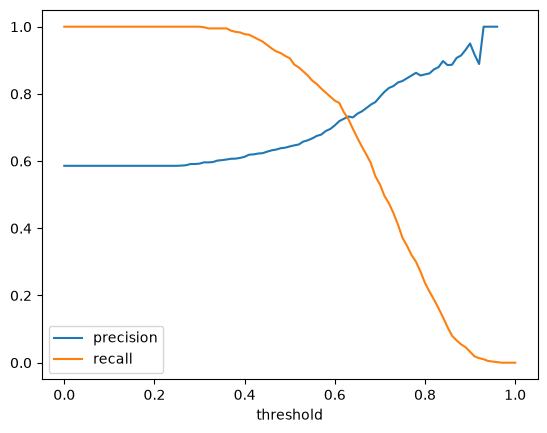

In [25]:
'''
Question 3: Precision and Recall at all thresholds
Now let's compute precision and recall for our model.

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
For each threshold, compute precision and recall
Plot them
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

- 0.43
- 0.63 <-- answer
- 0.73
- 0.83
'''

'''
Checks that belong to this question

Check	                                                         Why it matters
Use the validation probabilities y_pred and y_val from Q2	     The same model, the same data
101 thresholds: 0.00, 0.01, ..., 1.00	                         The task says step 0.01
Decision rule y_pred >= t	                                     Same as the lessons
At t = 0 recall is 1.0	                                         Everybody is flagged, so every real positive is caught
At very high t, precision can be NaN	                         Nobody is flagged, so tp + fp = 0, and 0/0 is NaN. Ignore those rows
Round the threshold to 2 decimals in the answer	                 Floating-point steps like 0.43000000001 are not options
'''

print(f"len(y_pred): {len(y_pred)}, len(y_val): {len(y_val)}")     # expect 1000 1000
print(f"y_pred.min(): {y_pred.min()}, y_pred.max(): {y_pred.max()}")

# Step 1: a table with the four counts for every threshold

rows = []

for t in np.linspace(0, 1, 101):
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    rows.append((round(float(t), 2), tp, fp, fn, tn))

df_scores = pd.DataFrame(rows, columns=['threshold', 'tp', 'fp', 'fn', 'tn'])

df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

df_scores.iloc[[0, 50, 100]] # thresholds 0.00, 0.50 and 1.00 as a quick look

# Step 2: plot both curves
# Precision should rise (roughly) as the threshold grows, and recall should fall. The point where they cross is the answer.
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.legend()

# Step 3: find the crossing
# The filter does two things: it drops NaN precision rows, and it drops rows where both precision and recall are 0. 
# The table then lists the five thresholds with the smallest gap.
valid = df_scores[
    df_scores.precision.notna()
    & ~((df_scores.precision == 0) & (df_scores.recall == 0))
].copy()

valid['diff'] = (valid.precision - valid.recall).abs()

valid.sort_values('diff').head(5)[['threshold', 'precision', 'recall', 'diff']]

max F1: 0.7576158940397352
thresholds reaching it: [0.41]
    threshold  precision    recall        f1
41       0.41   0.619048  0.976109  0.757616
42       0.42   0.620087  0.969283  0.756325
43       0.43   0.622517  0.962457  0.756032
45       0.45   0.628118  0.945392  0.754768
44       0.44   0.623608  0.955631  0.754717
46       0.46   0.632065  0.935154  0.754301
48       0.48   0.638298  0.921502  0.754190
40       0.40   0.612834  0.977816  0.753452


Text(0, 0.5, 'F1')

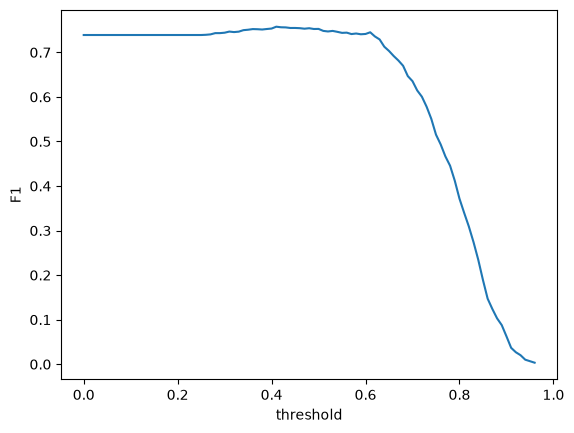

In [28]:
'''
Question 4: F1 score - threshold with the maximal F1
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

Plain text - 
F1 = 2 * (P * R) / (P + R)

Where 
P is precision and 
R is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

- 0.21
- 0.41 <-- answer
- 0.61
- 0.81
'''

'''
Checks that belong to this question

Check	                                                             Why it matters
Reuse df_scores from Q3 (101 rows)	                                 Same thresholds, same model
F1 is NaN where precision is NaN or where P + R = 0	                 Ignore those rows. max() skips them automatically
Look for ties, not just the first maximum	                         See below. This is where Q4 can trick you
Round the threshold to 2 decimals	                                 The options are 0.21, 0.41, 0.61, 0.81
'''

# Step 1: add F1 to the table
df_scores['f1'] = (
    2 * df_scores.precision * df_scores.recall
    / (df_scores.precision + df_scores.recall)
)

df_scores.f1.isna().sum() # This count shows how many thresholds have no F1 (nobody flagged, or both metrics zero).

# Step 2: the maximum and every threshold that reaches it
best_f1 = df_scores.f1.max()
tied = df_scores[np.isclose(df_scores.f1, best_f1)] # np.isclose treats values equal up to tiny floating-point differences as the same.

print('max F1:', best_f1)
print('thresholds reaching it:', tied.threshold.tolist())

# Step 3: the top rows, to see the shape
print(df_scores.sort_values('f1', ascending=False).head(8)[['threshold', 'precision', 'recall', 'f1']])

# Step 4: plot F1 against the threshold
plt.plot(df_scores.threshold, df_scores.f1)
plt.xlabel('threshold')
plt.ylabel('F1')

In [32]:
'''
Question 5: 5-fold cross-validation
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)
- Iterate over different folds of df_full_train
- Split the data into train and validation
- Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
- Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

0.001
0.007 <-- answer
0.013
0.060
'''

'''
Checks that belong to this question

Check	                                                                    Why it matters
Use df_full_train, which still contains converted	                        It’s the train + validation data (4,000 rows). We deliberately kept the target in it
Don’t use the test set	                                                    It stays untouched
Each fold: 3,200 rows for training, 800 for validation	                    Confirms the 5-way split
Same parameters as Q2: solver='liblinear', C=1.0, max_iter=1000	            They define the answer
Name the loop variables differently from df_train, df_val, y_train, y_val	Otherwise the loop overwrites your Q2 variables
np.std divides by n (the default). ddof=1 divides by n-1	                The homework doesn’t say which. We print both to see whether the rounded value differs
'''


print('converted' in df_full_train.columns)   # expect True
print(f"\nlen(df_full_train): {len(df_full_train)}")                     # expect 4000
print(f"\nfeatures:{features}")                               # 8 columns, no 'converted'

# Step 1: two helper functions
def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)

    return dv, model


def predict(df_x, dv, model):
    dicts = df_x[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

# Each fold trains its own DictVectorizer, so the encoding is learned from that fold’s training part only.
# Step 2: the cross-validation loop
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

fold_scores = []

for fold, (train_idx, val_idx) in enumerate(kfold.split(df_full_train)):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    y_tr = df_tr.converted.values
    y_va = df_va.converted.values

    dv_f, model_f = train(df_tr, y_tr, C=1.0)
    y_p = predict(df_va, dv_f, model_f)

    auc_f = float(roc_auc_score(y_va, y_p))
    fold_scores.append(auc_f)

    print(fold, len(df_tr), len(df_va), round(auc_f, 4))

# Step 3: the standard deviation
print('mean:', np.mean(fold_scores))
print('std (np.std, ddof=0):', np.std(fold_scores))
print('std (ddof=1):        ', np.std(fold_scores, ddof=1))

True

len(df_full_train): 4000

features:['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
0 3200 800 0.7306
1 3200 800 0.7296
2 3200 800 0.7363
3 3200 800 0.7412
4 3200 800 0.7209
mean: 0.7317269710972524
std (np.std, ddof=0): 0.006853233151022138
std (ddof=1):         0.007662147595670292


In [33]:
'''
Question 6: Hyperparameter Tuning - tuning C with cross-validation
Now let's use 5-Fold cross-validation to find the best parameter C

- Iterate over the following C values: [0.000001, 0.001, 1]
- Initialize KFold with the same parameters as previously
- Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
- Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which C leads to the best mean ROC AUC?

- 0.000001
- 0.001 <-- answer
- 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

C is the inverse regularization strength. 0.000001 means extremely strong regularization, and 1 is the default you used in Q2 and Q5.
'''

'''
Checks that belong to this question

Check	                                                                      Why it matters
A fresh KFold(n_splits=5, shuffle=True, random_state=1) for each C	          The same folds for every C, so the comparison is fair
Only C changes in the model parameters	                                      solver='liblinear', max_iter=1000 stay fixed
Round the mean and std to 3 decimals before comparing	                      The tie rules apply to the rounded values
Use np.std (default), as in Q5	                                              Consistency, and it matched the Q5 option
Keep the unrounded numbers too	                                              They show whether a tie is real or only apparent
The C = 1 row must reproduce Q5 (mean 0.7317, std 0.0069)	                  This verifies the new loop
'''

# Step 1: run the loop (it reuses train and predict from Q5)
results = {}

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        y_tr = df_tr.converted.values
        y_va = df_va.converted.values

        dv_f, model_f = train(df_tr, y_tr, C=C)
        y_p = predict(df_va, dv_f, model_f)

        scores.append(float(roc_auc_score(y_va, y_p)))

    mean_, std_ = float(np.mean(scores)), float(np.std(scores))
    results[C] = (round(mean_, 3), round(std_, 3))

    print(f'C={C:<10} mean={results[C][0]}  std={results[C][1]}   (raw: {mean_:.5f}, {std_:.5f})')

# Step 2: apply the selection rules
best_C = sorted(results, key=lambda C: (-results[C][0], results[C][1], C))[0]

print('best C:', best_C, results[best_C])

C=1e-06      mean=0.617  std=0.019   (raw: 0.61673, 0.01867)
C=0.001      mean=0.749  std=0.01   (raw: 0.74917, 0.01000)
C=1          mean=0.732  std=0.007   (raw: 0.73173, 0.00685)
